# Movie preferences: preliminary mining

This notebook explores **H2 (grouping similar users)** and prepares the simple prediction methods for **H3 (predicting a movie rating)**.

Read it from top to bottom:
1. Explore the ratings with charts (**EDA**).
2. Turn each user's rating history into numerical inputs (**features**).
3. Group users with similar features (**clustering**).
4. Measure simple rating predictions (**baselines**).
5. Save the results for the progress report.

We use all ratings in the published DuckDB warehouse and all users who have ratings. The warehouse is opened read-only. ETL has already checked the ratings; this notebook analyzes them rather than repeating the cleaning.

**Current scope:** clustering uses rating behavior and genres. Tags/tag-genome features are not loaded in this project's active warehouse. H3 here evaluates baselines only; a supervised feature model remains future work.

This is the combined preliminary deliverable. `01` checks source data, `02` provides standalone EDA, and `03`/`04` contain inactive earlier modeling workflows. You do not need to run those notebooks first; the warehouse must already be built. See the [run guide](../MINING_PRELIMINARY.md) for Docker instructions.

## Start: open the data

`Session()` opens the warehouse and creates a result folder. The functions imported below carry out each step; the calculations are in `src/mining/preliminary.py`.

In [1]:
from IPython.display import display, Image
import pandas as pd
from mining.preliminary import (
    Session, run_eda, prepare_features, run_clustering, run_baselines, finalize,
)

ctx = Session()

# Show the size and date range of the data we will analyze.
summary_columns = {
    'ratings': 'Rating events',
    'rating_users': 'Users with ratings',
    'rated_movies': 'Movies with ratings',
    'first_rating': 'First rating (UTC)',
    'last_rating': 'Last rating (UTC)',
}
display(pd.DataFrame([ctx.before])[list(summary_columns)].rename(columns=summary_columns))

open read-only warehouse


,Rating events,Users with ratings,Movies with ratings,First rating (UTC),Last rating (UTC)
0,20000263,138493,26744,1995-01-09 11:46:44,2015-03-31 06:40:02


## 1. Explore the data (EDA)

**EDA means exploratory data analysis:** look at counts and charts to understand the dataset before modeling.

We examine rating scores, activity over time, ratings per user/movie, and genre exposure. A rating records a user's score; it is not proof that they watched the movie.

**Avoid double counting:** if a movie belongs to two genres, its rating contributes 0.5 to each. The genre contributions still add up to one rating. No rating values are filled in or invented.

In [2]:
eda = run_eda(ctx)

print(f"Ratings analyzed: {eda['ratings']:,}")
print(f"Average rating: {eda['mean_rating']:.2f} out of 5")
print(f"Most common rating: {eda['most_common_rating']:.1f}")

EDA: aggregate every rating into user and movie summaries


Ratings analyzed: 20,000,263
Average rating: 3.53 out of 5
Most common rating: 4.0


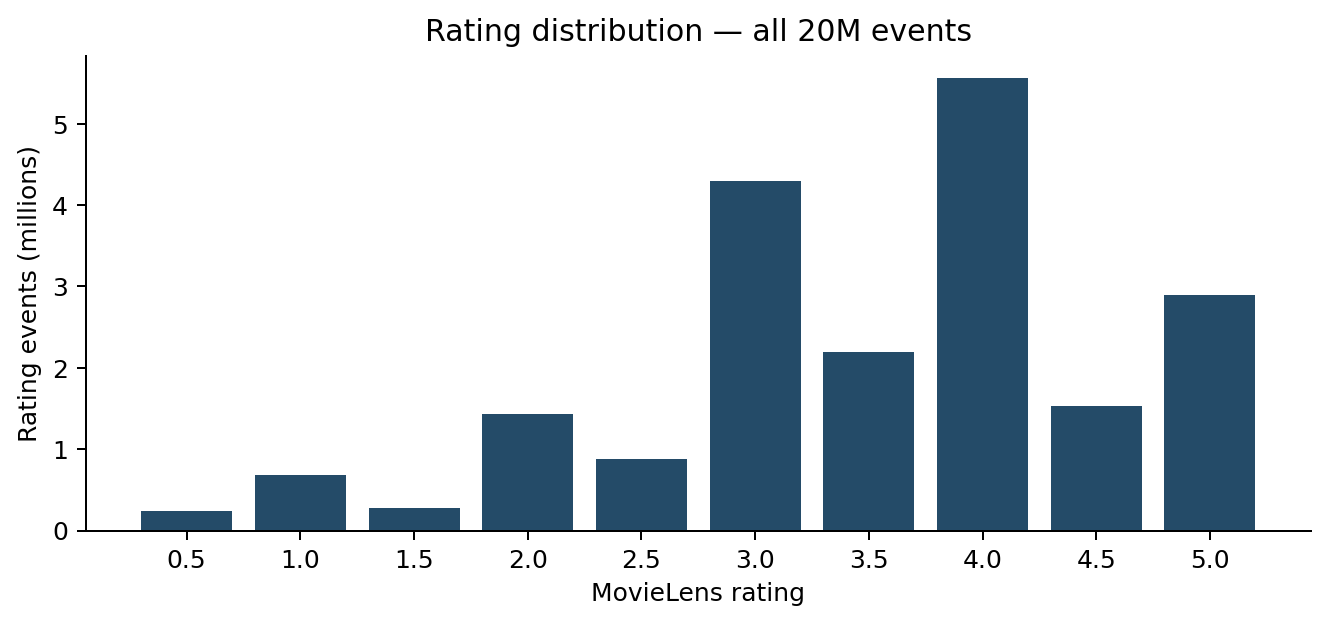

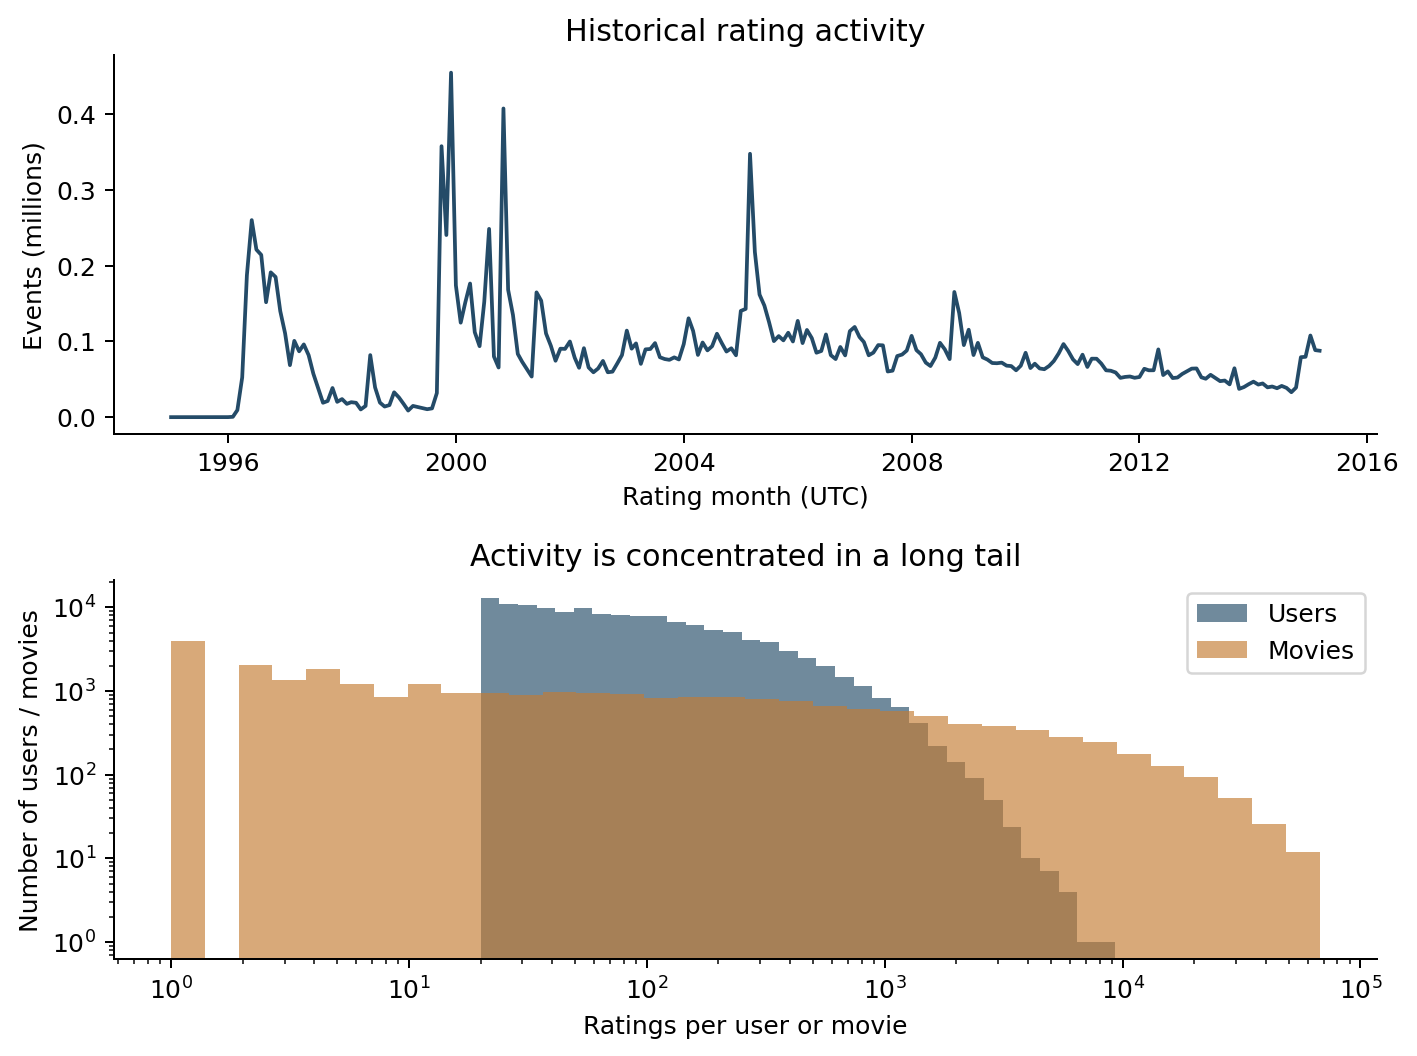

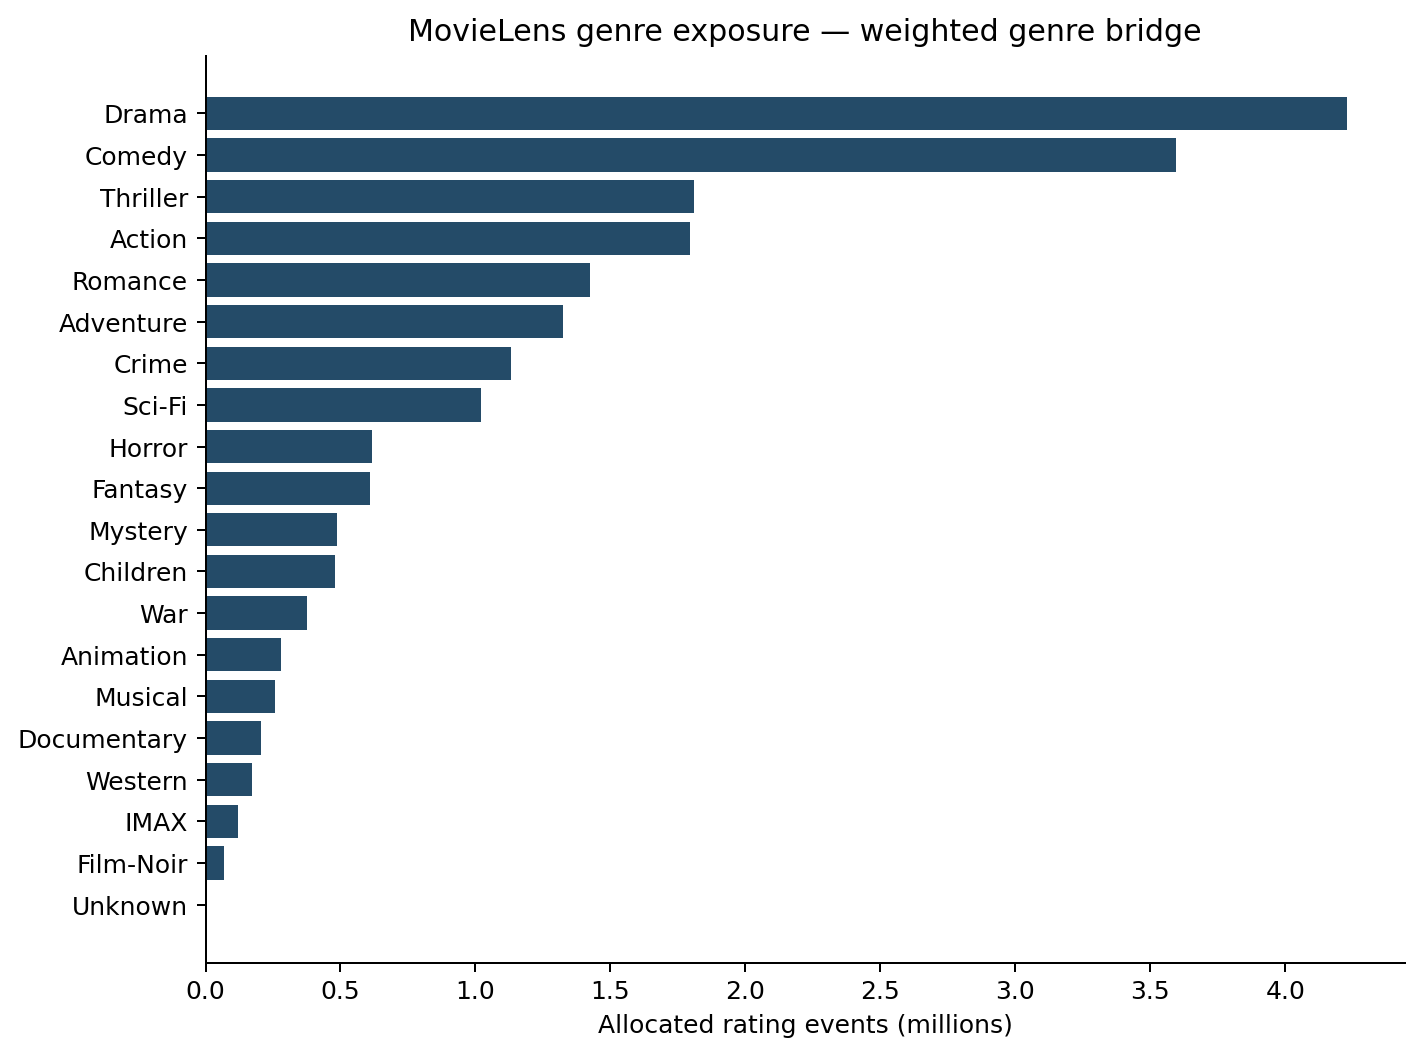

In [3]:
# Read the charts in order: scores, activity, then genres.
display(Image(filename=str(ctx.out / 'eda_rating_distribution.png')))
display(Image(filename=str(ctx.out / 'eda_activity.png')))
display(Image(filename=str(ctx.out / 'eda_genres.png')))

## 2. Describe each user with features (H2)

A **feature** is a number used as a model input. Here, **one row represents one user**, summarized from their full rating history.

| Feature | What it describes |
| --- | --- |
| Rating count | How frequently the user rates |
| Mean rating | Whether their scores tend to be high or low |
| Rating standard deviation | How much their scores vary |
| High-rating share | Fraction of their scores that are at least 4 |
| Activity span | Days between their first and last rating |
| Genre shares | How their ratings are distributed across genres |

The model uses **25 features**: five behavior features and 20 genre shares. Rating count and activity span use `log(1 + value)` to compress very large values. Before clustering, features are standardized so their scales are comparable.

A zero genre share means no observed ratings in that genre, not dislike. Full-history summaries are appropriate for describing users in H2. They must not be reused unchanged for H3, where future ratings would reveal information unavailable at prediction time.

In [4]:
users = prepare_features(ctx)

print(f"Users described: {len(users):,}")
print(f"Model features per user: {len(ctx.features)}")

# A small preview shows what one user row looks like.
preview_columns = {
    'rating_count': 'Ratings given',
    'mean_rating': 'Average score',
    'rating_std': 'Score variation',
    'high_rating_share': 'Share scoring 4 or more',
    'activity_span_days': 'Activity span (days)',
}
display(users[list(preview_columns)].head().rename(columns=preview_columns).round(3))

H2: build weighted genre shares for every rating-active user


Users described: 138,493
Model features per user: 25


,Ratings given,Average score,Score variation,Share scoring 4 or more,Activity span (days)
0,175,3.743,0.381,0.503,204
1,61,4.000,1.056,0.705,0
2,187,4.123,0.908,0.775,3
3,28,3.571,0.776,0.571,0
4,66,4.273,0.962,0.758,1


## 3. Find similar-user groups (H2)

**Clustering** groups similar rows without being given correct group labels. We use MiniBatchKMeans, which updates groups in small batches.

`k` means the number of groups. We compare **k = 2, 3, 4, 5** and make a preliminary choice using the highest silhouette score.

| Measure shown below | How to read it |
| --- | --- |
| Silhouette | Higher suggests clearer separation; near zero suggests overlapping groups |
| Seed stability (ARI) | Closer to 1 means changing the starting point produces similar groups |

All users are supplied to the model and assigned a group. Only silhouette is calculated on a fixed 2,000-user subset to keep evaluation affordable. Other full-user quality measures are saved in the results.

Group numbers are labels, not rankings. Inspect the sizes and genre profiles before naming groups such as "genre-focused users."

In [5]:
clustering = run_clustering(ctx, users)

# Show the main comparison; detailed metrics are saved automatically.
candidates = pd.DataFrame(clustering['candidates'])
comparison_columns = {
    'k': 'Number of groups',
    'silhouette': 'Silhouette (higher is better)',
    'seed_stability_ari_full_users': 'Seed stability (closer to 1 is better)',
}
display(candidates[list(comparison_columns)].rename(columns=comparison_columns).round(4))
print(f"Preliminary choice: {clustering['selected_k']} groups")

# Summarize the behavior of each group; genre profiles appear in the chart below.
profiles = pd.read_csv(ctx.out / 'cluster_profiles.csv')
profile_columns = {
    'cluster': 'Group',
    'users': 'Users',
    'rating_count': 'Average ratings per user',
    'mean_rating': 'Average user score',
    'high_rating_share': 'Average high-rating share',
}
display(profiles[list(profile_columns)].rename(columns=profile_columns).round(3))

H2: fit and evaluate full-user clustering candidates


H2: k=2, all 138,493 users


H2: k=3, all 138,493 users


H2: k=4, all 138,493 users


H2: k=5, all 138,493 users


,Number of groups,Silhouette (higher is better),Seed stability (closer to 1 is better)
0,2,0.1020,0.4049
1,3,0.0900,0.3626
2,4,0.0850,0.3347
3,5,0.0683,0.4657


Preliminary choice: 2 groups


,Group,Users,Average ratings per user,Average user score,Average high-rating share
0,0,78148,169.609,3.607,0.547
1,1,60345,111.785,3.653,0.553


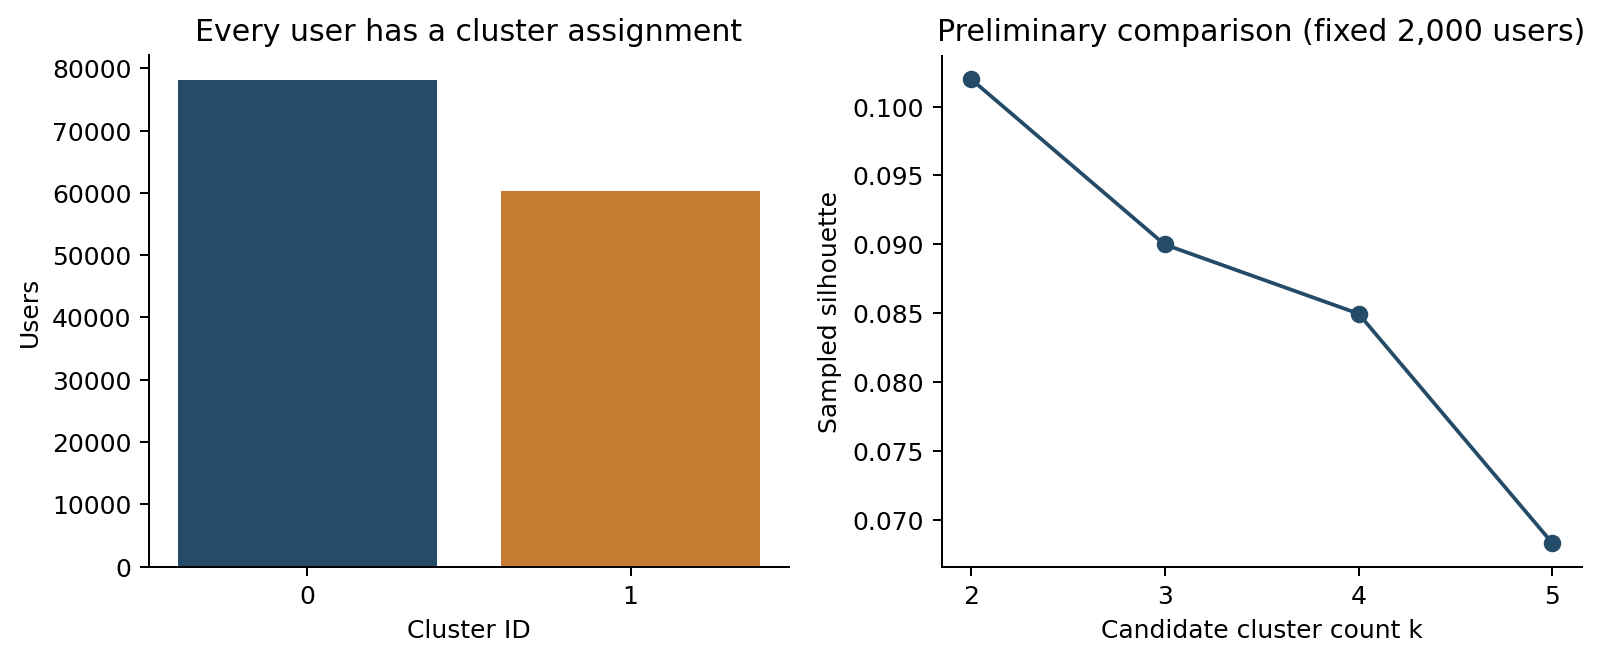

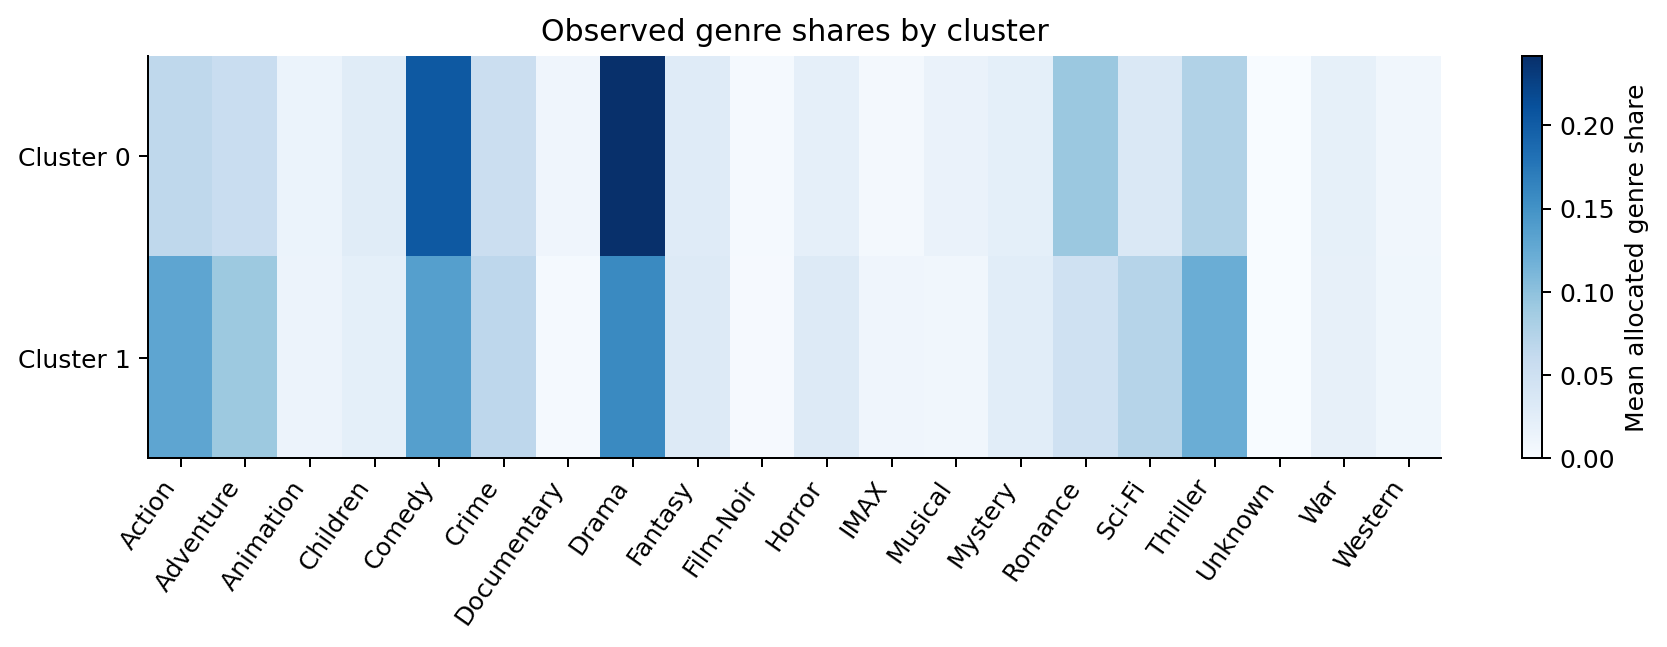

In [6]:
display(Image(filename=str(ctx.out / 'h2_cluster_sizes_quality.png')))
display(Image(filename=str(ctx.out / 'h2_genre_profiles.png')))

## 4. Measure simple rating predictions (H3 baselines)

A **baseline** is a simple method that a future supervised model should improve upon.

We split ratings by time: approximately **70% training, 15% validation, 15% test**. Earlier events come first; equal timestamps stay together.

- **Training:** calculate the averages used for prediction.
- **Validation:** evaluate methods while developing the experiment.
- **Test:** evaluate the chosen method on held-out ratings.

| Baseline | Prediction |
| --- | --- |
| Global average | The average score across training ratings |
| Movie average | That movie's average score in training; use the global average if it has no training ratings |

Validation/test ratings never contribute to these averages. This avoids **data leakage**, where answers accidentally enter the model inputs.

**MAE** is the average absolute prediction error. **RMSE** penalizes large errors more strongly. Both are in rating-score units; lower is better. For example, predicting 3.5 when the actual score is 4.0 gives an absolute error of 0.5.

Below we show test performance; validation results and additional diagnostics are also saved.

H3: determine chronological boundaries using every rating event


H3: evaluate global/movie averages using training statistics only


,Dataset,Rating events
0,train,14000184
1,validation,3000039
2,test,3000040


Global-average prediction: 3.511


,Baseline,RMSE,MAE
0,Global average,1.0177,0.7901
1,Movie average + fallback,0.9580,0.7298


Test ratings using the global fallback for unseen movies: 834,011


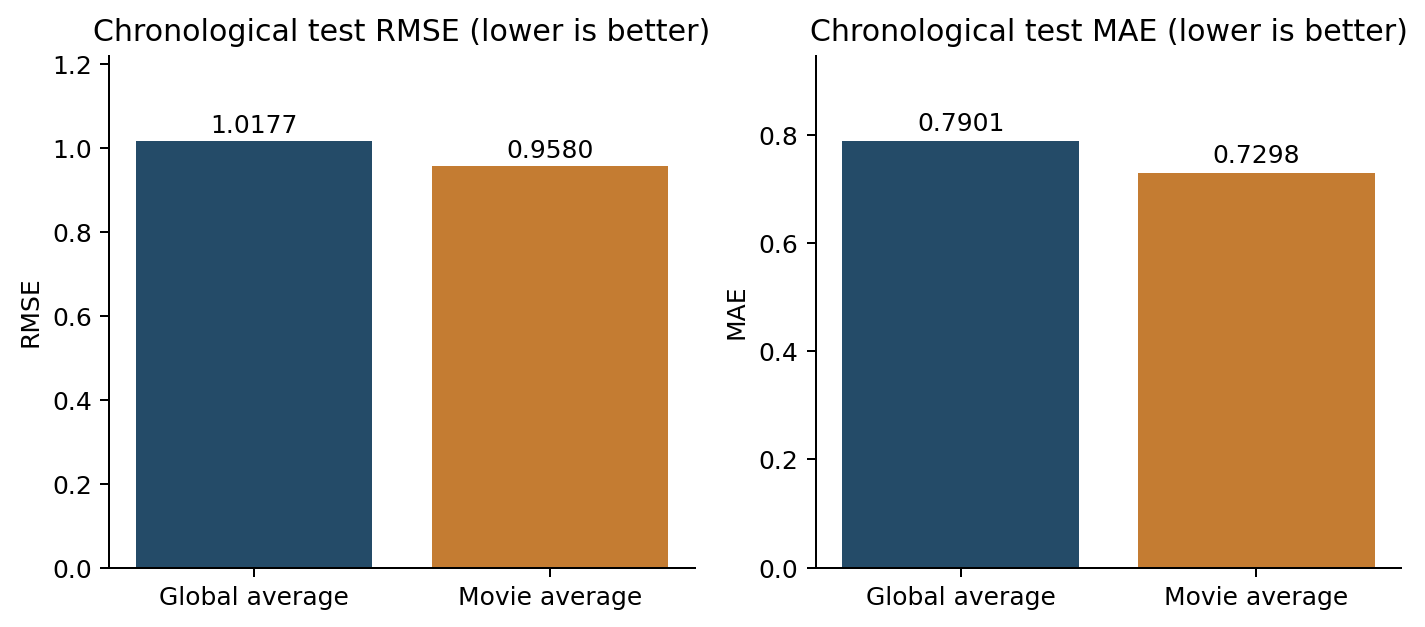

In [7]:
baselines = run_baselines(ctx)

split_columns = {'split': 'Dataset', 'ratings': 'Rating events'}
display(pd.DataFrame(baselines['splits'])[list(split_columns)].rename(columns=split_columns))
print(f"Global-average prediction: {baselines['training_global_mean']:.3f}")

# Compare both methods on exactly the same test ratings.
metrics = pd.DataFrame(baselines['metrics'])
test_metrics = metrics.loc[metrics['split'] == 'test'].copy()
test_metrics['model'] = test_metrics['model'].replace({
    'global_average': 'Global average',
    'movie_average': 'Movie average + fallback',
})
display(test_metrics[['model', 'rmse', 'mae']].rename(
    columns={'model': 'Baseline', 'rmse': 'RMSE', 'mae': 'MAE'},
).round(4))

fallback_count = test_metrics.loc[
    test_metrics['model'] == 'Movie average + fallback', 'global_fallback_events',
].iloc[0]
print(f"Test ratings using the global fallback for unseen movies: {fallback_count:,}")
display(Image(filename=str(ctx.out / 'h3_baseline_errors.png')))

## 5. Save the experiment

Save the tables, charts, user features, clustering model and report section. The saved run also records the source ETL run, settings and software versions so the experiment can be reproduced.

The final check compares the warehouse's rating counts, score sum and date range before and after analysis.

In [8]:
result = finalize(ctx, eda, clustering, baselines)

print("Run status:", result['status'])
print("Warehouse summary unchanged:", result['warehouse_signature_unchanged'])
print("Saved results:", ctx.out)
print("Report section:", ctx.root / 'REPORT_SECTION.md')

save measured results and report section


complete


Run status: success
Warehouse summary unchanged: True
Saved results: reports/results/mining_preliminary/20261012T105513014787Z
Report section: reports/results/mining_preliminary/REPORT_SECTION.md


## What can we conclude?

- **H2:** compare silhouette, stability and group profiles above. Weak separation or unstable assignments do not establish distinct user archetypes, even though the algorithm produces groups.
- **H3:** these results establish reference errors. They do not yet show that a supervised model beats the baselines.

**Next work:** improve and evaluate H2 features; build an H3 supervised model using history available before each prediction. Training features must exclude their own target rating and future ratings. Address the missing tag/tag-genome features before claiming the full hypotheses have been tested. Current TMDb scores/popularity are excluded because they were not observed at the historical rating times.